=== SAMOGŁOSKA ===
Liczba próbek: 21965
Czas trwania: 1.37 s
Kształt Log-mel [cechy, T]: (64, 138)
Kształt MFCC [cechy, T]: (13, 138)
Układ dla sieci rekurencyjnej (RNN) [T, cechy]: (138, 64)



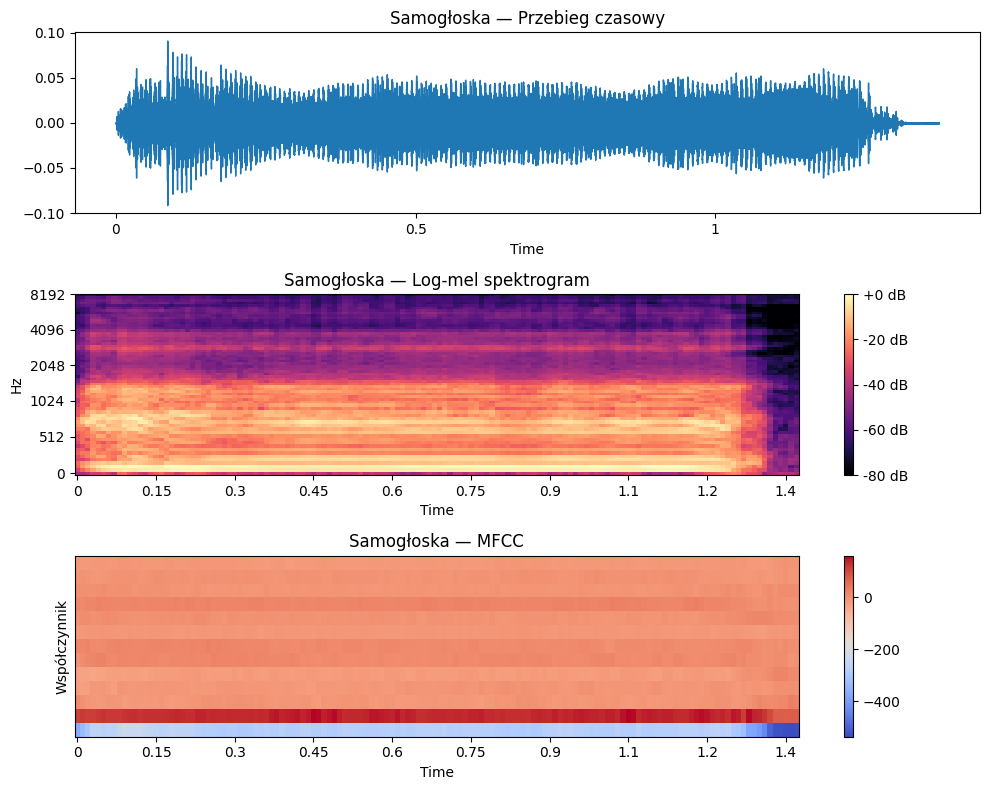

=== WYRAZ ===
Liczba próbek: 11285
Czas trwania: 0.71 s
Kształt Log-mel [cechy, T]: (64, 71)
Kształt MFCC [cechy, T]: (13, 71)
Układ dla sieci rekurencyjnej (RNN) [T, cechy]: (71, 64)



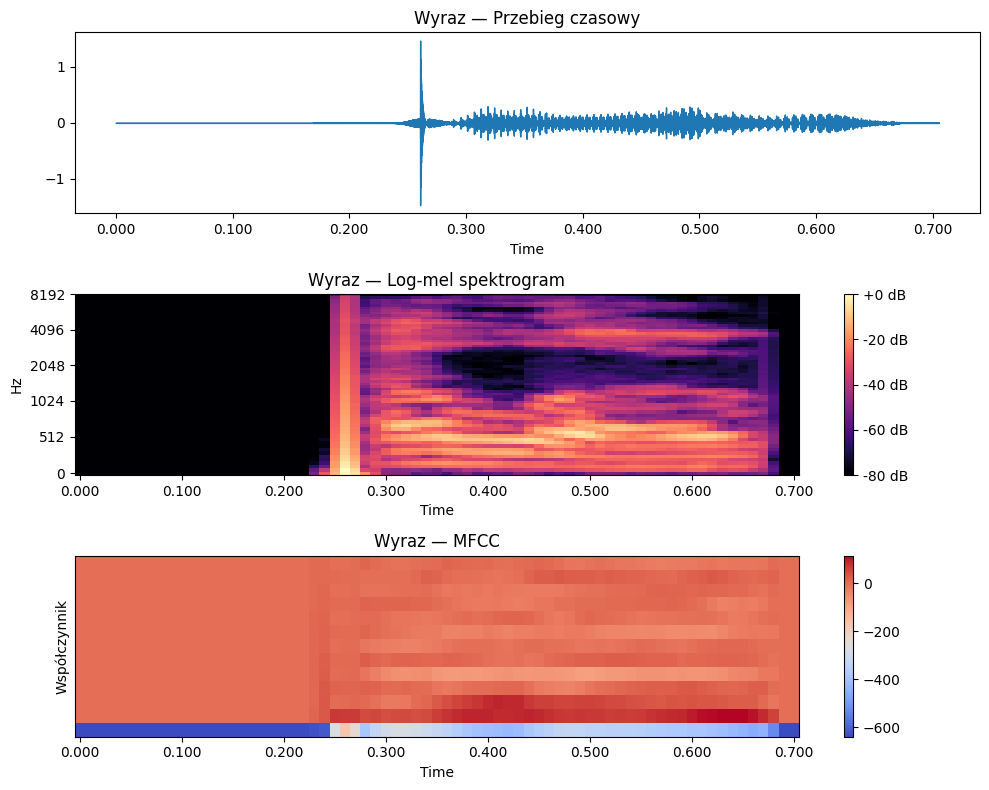

=== ZDANIE ===
Liczba próbek: 84269
Czas trwania: 5.27 s
Kształt Log-mel [cechy, T]: (64, 527)
Kształt MFCC [cechy, T]: (13, 527)
Układ dla sieci rekurencyjnej (RNN) [T, cechy]: (527, 64)



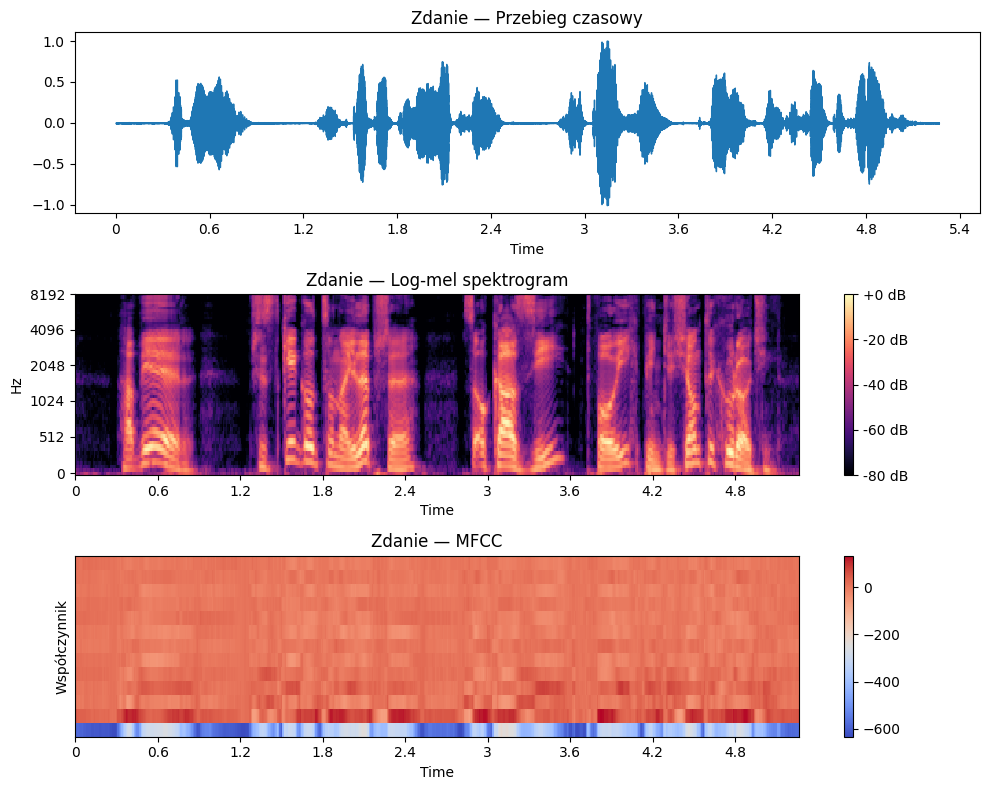

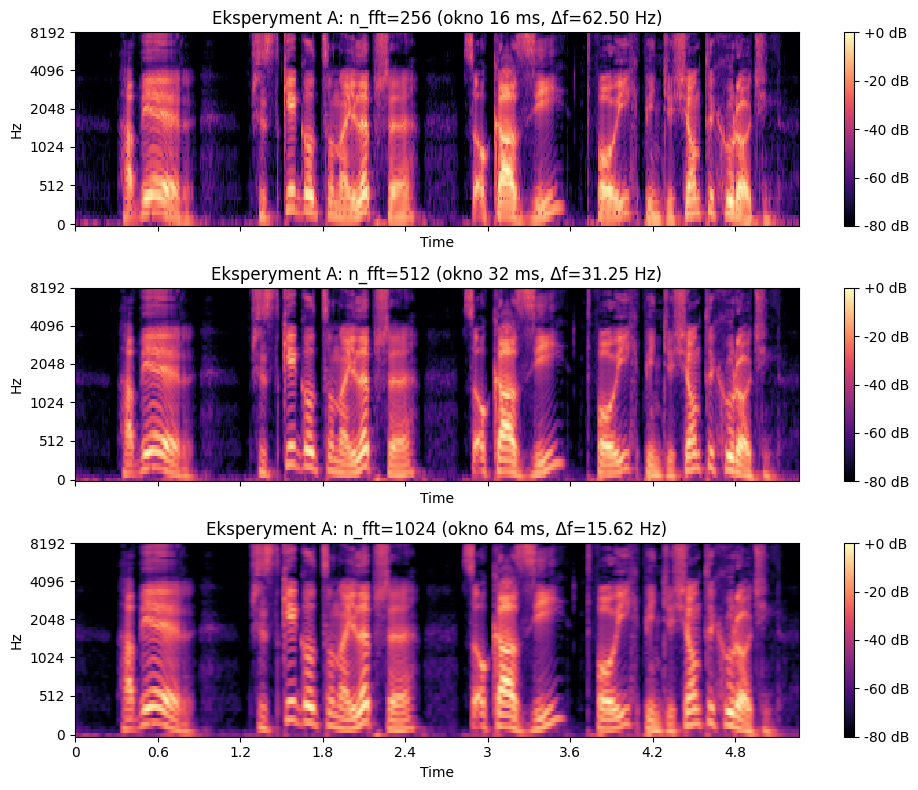

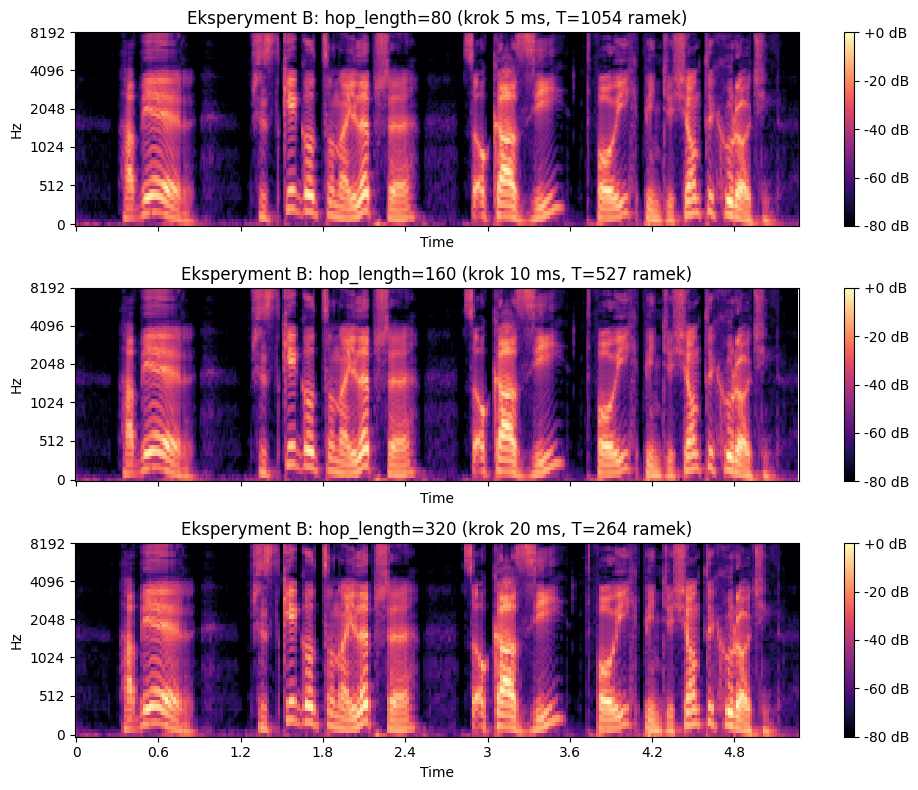

In [3]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 64
N_MFCC = 13

pliki = {
    "Samogłoska": "samogloska.wav",
    "Wyraz": "slowo_hello.mp3",
    "Zdanie": "zyczenia_dla_xaviera.wav"
}

def wczytaj_audio(sciezka):
    y, sr = librosa.load(sciezka, sr=SR, mono=True)
    return y.astype(np.float32), sr

def oblicz_reprezentacje(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, n_mfcc=N_MFCC):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    S_db = librosa.power_to_db(S, ref=np.max)
    M = librosa.feature.mfcc(S=S_db, n_mfcc=n_mfcc)
    return S_db, M

def generuj_wykresy(y, sr, tytul, n_fft=N_FFT, hop_length=HOP_LENGTH):
    S_db, M = oblicz_reprezentacje(y, sr, n_fft=n_fft, hop_length=hop_length)

    print(f"=== {tytul.upper()} ===")
    print(f"Liczba próbek: {len(y)}")
    print(f"Czas trwania: {len(y)/sr:.2f} s")
    print(f"Kształt Log-mel [cechy, T]: {S_db.shape}")
    print(f"Kształt MFCC [cechy, T]: {M.shape}")
    print(f"Układ dla sieci rekurencyjnej (RNN) [T, cechy]: {S_db.T.shape}\n")

    fig, ax = plt.subplots(3, 1, figsize=(10, 8))

    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set_title(f"{tytul} — Przebieg czasowy")

    img1 = librosa.display.specshow(
        S_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel",
        ax=ax[1], vmin=-80, vmax=0
    )
    ax[1].set_title(f"{tytul} — Log-mel spektrogram")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        M, sr=sr, hop_length=hop_length, x_axis="time", ax=ax[2]
    )
    ax[2].set_title(f"{tytul} — MFCC")
    ax[2].set_ylabel("Współczynnik")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.savefig(f"{tytul.lower()}_wykres.png", dpi=150)
    plt.show()

dane_audio = {}
for tytul, sciezka in pliki.items():
    y, sr = wczytaj_audio(sciezka)
    dane_audio[tytul] = (y, sr)
    generuj_wykresy(y, sr, tytul)

y_zdanie, sr_zdanie = dane_audio["Zdanie"]

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for i, n_fft in enumerate([256, 512, 1024]):
    S_db, _ = oblicz_reprezentacje(y_zdanie, sr_zdanie, n_fft=n_fft, hop_length=160)
    img = librosa.display.specshow(
        S_db, sr=sr_zdanie, hop_length=160, x_axis="time", y_axis="mel",
        ax=ax[i], vmin=-80, vmax=0
    )
    okno_ms = (n_fft / sr_zdanie) * 1000
    df = sr_zdanie / n_fft
    ax[i].set_title(f"Eksperyment A: n_fft={n_fft} (okno {okno_ms:.0f} ms, Δf={df:.2f} Hz)")
    fig.colorbar(img, ax=ax[i], format="%+2.0f dB")
plt.tight_layout()
plt.savefig("eksperyment_A.png", dpi=150)
plt.show()

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for i, hop in enumerate([80, 160, 320]):
    S_db, _ = oblicz_reprezentacje(y_zdanie, sr_zdanie, n_fft=512, hop_length=hop)
    img = librosa.display.specshow(
        S_db, sr=sr_zdanie, hop_length=hop, x_axis="time", y_axis="mel",
        ax=ax[i], vmin=-80, vmax=0
    )
    krok_ms = (hop / sr_zdanie) * 1000
    ax[i].set_title(f"Eksperyment B: hop_length={hop} (krok {krok_ms:.0f} ms, T={S_db.shape[1]} ramek)")
    fig.colorbar(img, ax=ax[i], format="%+2.0f dB")
plt.tight_layout()
plt.savefig("eksperyment_B.png", dpi=150)
plt.show()